# DX703 Final Project — Final Code Notebook (Part A)

**Due Date:** Sunday, December 6, 2026 at 11:59 p.m. (2-hour, 1-minute grace period)

**No late submissions!**

**Submit:** This completed `.ipynb` notebook and the separate technical report (Part B, `.pdf`).  

## Purpose

Build on your work from the **DX703 Final Project Milestone: Data Exploration and Baseline Modeling**. Using your previously selected dataset and established train/validation/test split, you will:

- Develop and evaluate a custom neural network, including experiments to improve its performance.
- Implement a pretrained model and investigate transfer-learning strategies.
- Compare both approaches with your milestone baseline using validation results.
- Select and finalize the best model based on predictive performance and computational constraints.
- Evaluate the selected model on the held-out test set and analyze its errors.

This assignment supports **both Food-101 (image classification) and HuffPost News Category (text classification)**. Use architectures and preprocessing appropriate to your dataset while addressing the same multiclass-classification objectives.

## Grading Overview

| Problem | Focus | Points |
|---|---|---:|
| 1 | Setup, preprocessing, and baseline recap | **10** |
| 2 | Custom neural network and experiments | **35** |
| 3 | Pretrained model and transfer learning | **35** |
| 4 | Comparison, selection, and final training | **30** |
| 5 | Final test evaluation and error analysis | **25** |
| **Total** | | **135** |

## Important Submission Requirements

- **Preserve the notebook structure.** Complete the provided code and Markdown cells without deleting or replacing them. You may add additional cells as needed. Keep all required results and written responses in their designated locations to support reliable grading without rerunning expensive experiments.

- **Submit a notebook with executed results.** Include the relevant outputs, training histories, comparison tables, metrics, and plots. Code alone is not sufficient evidence for full credit if its required results are missing.

- **Complete the written responses.** Answer questions in the designated Markdown cells, replacing the *Your Answer* placeholders. Provide concise but substantive explanations supported by your experimental results. More extensive discussion belongs in the technical report.

- **Document your experiments.** Use organized, reproducible code, consistent random seeds where practical, and clearly identified model configurations. Avoid hard-coded local paths or dependencies on inaccessible private files.

- **Manage computational constraints responsibly.** You may use documented, reproducible subsets when full-dataset experiments are impractical. Preserve the original train/validation/test separation, explain how subsets were selected, and make model comparisons on consistent or explicitly comparable validation data. Do not present subset results as full-dataset results.

- **Protect the held-out test set.** Use validation results exclusively for model development, tuning, and selection. The final model and evaluation protocol must be fixed in Problem 4 before examining test results in Problem 5. Do not revise the model based on test performance.

- **Preserve expensive experimental results.** You are not required to rerun computationally expensive training during grading. Save the relevant outputs, training configurations, and checkpoints when practical. Your notebook should document how the results were obtained and how the final evaluation could be reproduced.

- **Coordinate with the technical report.** The notebook should demonstrate your implementation, experimental evidence, and concise interpretations. The separate technical report (Part B) will present a more complete discussion of methodology, results, limitations, and conclusions.

## Problem 0 — Dataset Selection (0 pts)

Identify the dataset used for your final project. It must be the same dataset you used in the milestone.

**Selected dataset:** Food-101

## Problem 1 — Setup, Preprocessing, and Baseline Recap (10 pts)

Reuse the dataset, split, and baseline developed in your milestone. You may improve your preprocessing pipeline, but document changes and retain a fair validation comparison. **Do not repeat all the milestone EDA or write another lengthy dataset description.**

- **A. Reusable data pipeline (4 pts)**
- **B. Baseline evidence (4 pts)**
- **C. Milestone-to-final transition (2 pts)**

### Part A — Reusable Data Pipeline (4 pts)

**Implementation (3 pts):**

- Set random seeds;
- import required packages;
- load the chosen dataset or saved splits;
- reuse exactly the established train/validation/test partition;
- implement the final preprocessing/data-loading functions or pipelines needed for modeling.
- Fit learned preprocessing only on training data, and apply training-only augmentation only to training examples.
- **Category consolidation (optional):** You may combine closely related target categories when justified by their meaning (e.g., *Arts* and *Arts and Leisure* in HuffPost). If you consolidated categories in the milestone, preserve that mapping. If you decide to consolidate categories now, apply the mapping consistently across all three splits without changing which observations belong to each split. **Category consolidation is not required.**
- Show split sizes and relevant shape/type sanity checks. **Do not evaluate on the test set.**

**Explanation (1 pt):** Summarize any preprocessing changes relative to the milestone and why they were made. If you consolidated target categories, explain which categories were combined and why. If you changed the category definitions since the milestone, explain how this affects comparisons with your original baseline; models using different category definitions are not directly comparable. If there are no changes, say so.

In [1]:
# ============================================
# Useful Imports
# ============================================

# --- Standard Libraries
import os
import time
import math
import random
from collections import Counter

# --- Core Data / Numerics
import numpy as np
import pandas as pd

# --- Visualization
import matplotlib.pyplot as plt
# import seaborn as sns              # optional
import matplotlib.ticker as mticker  # optional (for formatted axes)

# --- NLP / Tokenization
import spacy                         # used for text preprocessing (HuffPost)

# --- Progress Tracking
from tqdm import tqdm                # optional (nice for loops)

from IPython.display import display

# --- TensorFlow / Keras (Deep Learning)
import tensorflow as tf
from tensorflow.keras import layers, models, Input, callbacks, regularizers, initializers
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay, ExponentialDecay
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.layers import (
    Dense, Dropout, Flatten, MaxPooling2D, Conv2D,
    SeparableConv2D, GlobalAveragePooling2D, GlobalMaxPooling2D, BatchNormalization,
    MaxPooling2D, Input, Rescaling, RandomFlip, RandomRotation, RandomZoom, RandomContrast,
    RandomBrightness, RandomTranslation, RandomCrop
)
from keras import Sequential

# --- Hugging Face Datasets
from datasets import load_dataset, DatasetDict, Array3D, Features
from datasets.features import ClassLabel

# --- Image operations
from PIL import Image, ImageOps

# --- (Optional) Classical ML Baseline Tools
# from sklearn.pipeline import Pipeline
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score


# ============================================
# Global Configuration & Small Utilities
# ============================================

# Reproducibility
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
tf.keras.utils.set_random_seed(random_seed)   # sets Python, NumPy, and TensorFlow seeds

# Food 101 num classes
num_classes = 101

# Utility: format seconds as HH:MM:SS

"""
Example usage to time your code:

start_time = time.time()
# ... your code here ...
print("Execution Time:", format_hms(time.time() - start_time))
"""

def format_hms(seconds: float) -> str:
    """Convert seconds to HH:MM:SS format."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
I0000 00:00:1795635736.624804    2487 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795635736.968978    2487 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795635738.163910    2487 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different compu

In [2]:
food_all = load_dataset("ethz/food101", split="train+validation")  # ~101k images total
label_col = "label"

# Sanity check the label column
assert label_col in food_all.features
assert isinstance(food_all.features[label_col], ClassLabel)

food_label_names = food_all.features[label_col].names
print(f"Total images: {len(food_all):,}  |  Classes: {len(food_label_names)}")

Total images: 101,000  |  Classes: 101


In [3]:
# Duplicate and black/white images identified in EDA
indices_to_remove = {
    18114,  # Keep the first; both prime_rib and steak are valid labels.
    2781,   # Menu photo, not food; hamburger label is incorrect.
    2982,   # Menu photo, not food; hamburger label is incorrect.
    22486,  # Keep the omelette-labeled image; pancake label is incorrect.
    35932,  # Duplicate dumplings image; keep the other copy.
    50919,  # Duplicate pho image; keep the other copy.
    50980,  # Duplicate pho image; keep the other copy.
    99649,  # Duplicate churros image; keep the other copy.
    100572, # Duplicate paella image; keep the other copy.
    18508, # Black and White image
    23754, # Black and White image
    56094 # Black and White image
}

In [4]:
keep_indices = [
    i for i in range(len(food_all))
    if i not in indices_to_remove
]
food_all_clean = food_all.select(keep_indices)

print(f"Removed {len(food_all) - len(food_all_clean)} rows")

Removed 12 rows


In [5]:
label_col = "label"

# Hold out 10% for testing.
temp_split = food_all_clean.train_test_split(
    test_size=0.10,
    seed=42,
    stratify_by_column=label_col,
)

# Split 1/9 of the remaining 90% for validation (10% of the full dataset).
train_val_split = temp_split["train"].train_test_split(
    test_size=1 / 9,
    seed=42,
    stratify_by_column=label_col,
)

food_splits = DatasetDict({
    "train": train_val_split["train"],
    "validation": train_val_split["test"],
    "test": temp_split["test"],
})

for name, split in food_splits.items():
    print(f"{name}: {len(split):,} images")

train: 80,790 images
validation: 10,099 images
test: 10,099 images


In [6]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32
# 128 x 128 (3x less pixels than 224x224 so faster epochs)
IMAGE_SIZE = (128, 128)

# Parallelize workers used by to_tf_dataset to load batches
NUM_WORKERS = 4

# Hugging Face .map() passes one example dictionary at a time.
# Keep this step deterministic; random augmentation belongs in the
# TensorFlow training pipeline so it can vary across epochs.
def preprocess_example(example):
    # 1. Ensure each row is already in RGB (We already have checked this at this point but it is a safe cast)
    image = example["image"].convert("RGB")

    # 2. Resize and Crop
    image = ImageOps.fit(image, IMAGE_SIZE, method=Image.Resampling.BILINEAR)

    return {
        "image": np.asarray(image, dtype=np.uint8),
        "label": int(example["label"]),
    }

# Tell Hugging Face the fixed shape and type of the processed images.
processed_features = Features({
    "image": Array3D(shape=(128, 128, 3), dtype="uint8"),
    "label": food_splits["train"].features["label"],
})

# Apply the deterministic preprocessing to each existing split.
# The split names remain "train", "validation", and "test".
processed_splits = food_splits.map(
    preprocess_example,
    remove_columns=food_splits["train"].column_names,
    features=processed_features,
)


def make_tf_dataset(split, *, training=False):
    # Keep images uint8 (0-255 all the way through the tf.data pipeline. Float32 is 4x larger)
    return split.to_tf_dataset(
        columns=['image'],
        label_cols=['label'],
        batch_size=BATCH_SIZE,
        shuffle=training,
        num_workers=NUM_WORKERS,
        prefetch=True
    )

train_ds = make_tf_dataset(processed_splits["train"], training=True)
val_ds = make_tf_dataset(processed_splits["validation"])
test_ds = make_tf_dataset(processed_splits["test"])

/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/datasets/arrow_dataset.py:410: FutureWarning: The output of `to_tf_dataset` will change when a passing single element list for `labels` or `columns` in the next datasets version. To return a tuple structure rather than dict, pass a single string.
Old behaviour: columns=['a'], labels=['labels'] -> (tf.Tensor, tf.Tensor)  
             : columns='a', labels='labels' -> (tf.Tensor, tf.Tensor)  
New behaviour: columns=['a'],labels=['labels'] -> ({'a': tf.Tensor}, {'labels': tf.Tensor})  
             : columns='a', labels='labels' -> (tf.Tensor, tf.Tensor) 
  warnings.warn(
I0000 00:00:1795635741.131795    2487 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5527 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Ti, pci bus id: 0000:01:00.0, compute capability: 8.9


In [7]:
preprocessing_layers = Sequential([
    Rescaling(1.0 / 255), # uint8 [0,255] to float32 [0,1]
    RandomFlip("horizontal"),
    RandomBrightness(0.1, value_range=(0.0, 1.0)),
    RandomContrast(0.1),
], name='preprocessing_layers')

In [26]:
def plot_learning_curves(hist, title, verbose=True):
    
    val_losses = hist.history['val_loss']
    min_val_loss = min(val_losses)
    min_val_epoch = val_losses.index(min_val_loss)
    val_acc_at_min_loss = hist.history['val_accuracy'][min_val_epoch]

    epochs = range(1, len(val_losses) + 1)  # epoch numbers starting at 1

    fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

    # --- Loss Plot ---
    axs[0].plot(epochs, hist.history['loss'], label='train loss')
    axs[0].plot(epochs, hist.history['val_loss'], label='val loss')
    axs[0].scatter(min_val_epoch + 1, min_val_loss, color='red', marker='x', s=50, label='min val loss')
    axs[0].set_title(f'{title} - Categorical Cross-Entropy Loss')
    axs[0].set_ylabel('Loss')
    axs[0].legend()
    axs[0].grid(True)

    # --- Accuracy Plot ---
    axs[1].plot(epochs, hist.history['accuracy'], label='train acc')
    axs[1].plot(epochs, hist.history['val_accuracy'], label='val acc')
    axs[1].scatter(min_val_epoch + 1, val_acc_at_min_loss, color='red', marker='x', s=50, label='acc @ min val loss')
    axs[1].set_title(f'{title} - Accuracy')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('Accuracy')
    axs[1].legend()
    axs[1].grid(True)
    axs[1].set_ylim(0, 1.05)

    plt.tight_layout()
    plt.show()

    if verbose:
        print(f"Final Training Loss:            {hist.history['loss'][-1]:.4f}")
        print(f"Final Training Accuracy:        {hist.history['accuracy'][-1]:.4f}")
        print(f"Final Validation Loss:          {hist.history['val_loss'][-1]:.4f}")
        print(f"Final Validation Accuracy:      {hist.history['val_accuracy'][-1]:.4f}")
        print(f"Minimum Validation Loss:        {min_val_loss:.4f} (Epoch {min_val_epoch + 1})")
        print(f"Validation Accuracy @ Min Loss: {val_acc_at_min_loss:.4f}")

    results[title] = (val_acc_at_min_loss,min_val_epoch + 1)

results = {}

def print_results():
    for title, (acc, ep) in sorted(results.items(), 
                                   key=lambda kv: kv[1][0],   # kv[1] is (acc, epoch); [0] is acc
                                   reverse=True
                                  ):
        print(f"{title:<40}\t{acc:.4f}\t{ep}")

# Uses globals: train_ds, val_ds, test_ds

def train_and_test(model, 
                   epochs        = 500,
                   lr_schedule   = 1e-3,
                   optimizer     = "Adam",
                   title         = "Learning Curves",
                   use_early_stopping = True,
                   patience      = 5,
                   min_delta     = 0.0001,
                   callbacks     = [],
                   verbose       = 0,
                   return_history = False,
                   evaluate_test_set = False
                  ):

    print(f"\n{title}\n")

    # Choose optimizer
    if optimizer == "Adam":
        opt = Adam(learning_rate=lr_schedule)
    else:
        opt = optimizer

    # Compile
    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=min_delta,
        restore_best_weights=True,
        verbose=verbose
    )

    cbs = ([early_stop] if use_early_stopping else []) + callbacks

    start = time.time()

    # Fit on tf.data datasets (already batched)
    history = model.fit(
        train_ds,
        epochs=epochs,
        validation_data=val_ds,
        callbacks=cbs,
        verbose=verbose
    )

    # Determine best validation accuracy
    if use_early_stopping and hasattr(early_stop, "best_epoch") and early_stop.best_epoch is not None:
        best_epoch = early_stop.best_epoch
        best_acc   = history.history['val_accuracy'][best_epoch]
    else:
        best_epoch = int(np.argmax(history.history['val_accuracy']))
        best_acc   = history.history['val_accuracy'][best_epoch]

    plot_learning_curves(history, title=title)

    # Evaluate on tf.data test set
    if evaluate_test_set:
        test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

        print(f"\nTest Loss: {test_loss:.4f}")
        print(f"Test Accuracy: {test_accuracy:.4f}")
        print(f"\nValidation-Test Gap (accuracy): {abs(best_acc - test_accuracy):.6f}")

    end = time.time()
    print(f"\nExecution Time: " + format_hms(end-start))

    if return_history:
        return history


**Your Answer:**

> Summarize any preprocessing changes relative to the milestone and why they were necessary. If there are no changes, say so.

I did not make any preprocessing changes relative to the milestone. I retained the cleaning steps to remove black and white and duplicate images. I also retained the same
preprocessing pipeline.

### Part B — Recover the Milestone Baseline (4 pts)

**Evidence (3 pts):** 

- Supply the baseline architecture/configuration and its previously obtained validation results, including the principal selection metric.
- Include training history or relevant plots where applicable.
- Reuse saved milestone results where practical; baseline retraining is not required solely for this section.

**Explanation (1 pt):** State the baseline's primary limitation and the validation metric that will be used to compare later models. Keep metric definitions and validation samples consistent across comparisons.

In [9]:
he = initializers.HeNormal()

baseline_model = Sequential([
    Input(shape=(*IMAGE_SIZE, 3)), # 128x128 with 3 channels (RGB)
    preprocessing_layers,  # rescale + augment during training
    Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
    MaxPooling2D(),
    GlobalAveragePooling2D(),  # (64, 64, 32) -> (64,)

    # Compact head
    Dense(128, activation='relu', kernel_initializer=he),
    Dense(num_classes, activation='softmax')
])


Baseline Model



/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795635741.992812    2487 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1795635743.065620    3088 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795635743.402703    3090 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment v

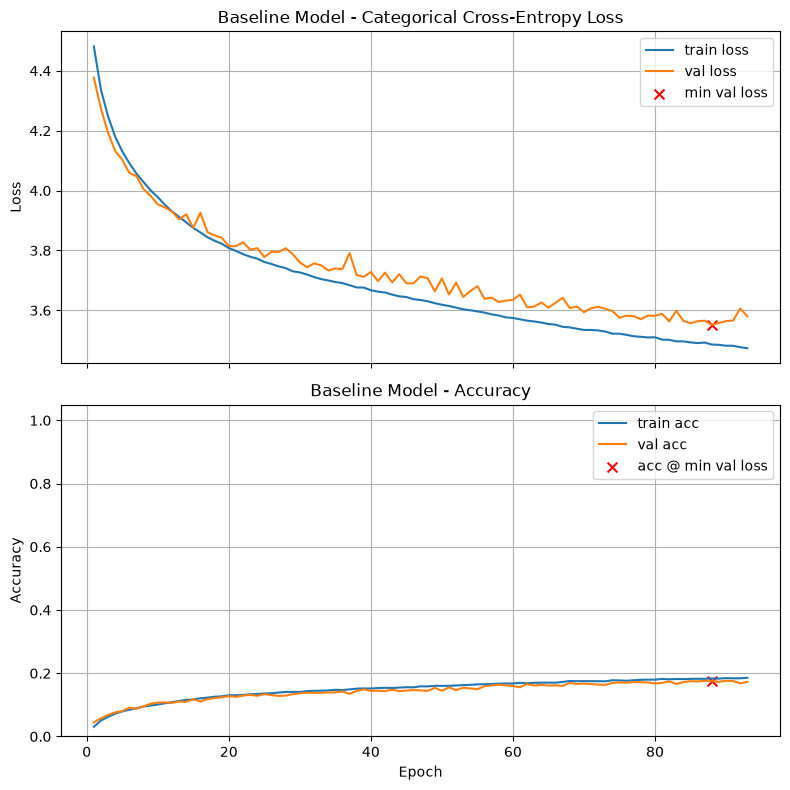

Final Training Loss:            3.4735
Final Training Accuracy:        0.1857
Final Validation Loss:          3.5801
Final Validation Accuracy:      0.1727
Minimum Validation Loss:        3.5515 (Epoch 88)
Validation Accuracy @ Min Loss: 0.1755

Execution Time: 00:43:44


In [10]:
baseline_history = train_and_test(baseline_model, title="Baseline Model", verbose=0, return_history=True)

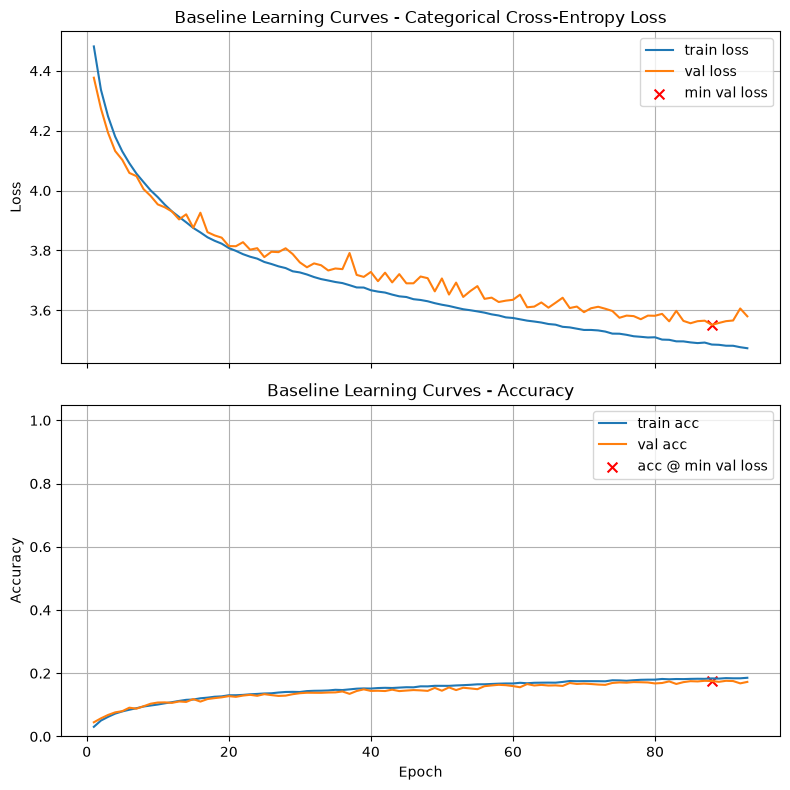

Final Training Loss:            3.4735
Final Training Accuracy:        0.1857
Final Validation Loss:          3.5801
Final Validation Accuracy:      0.1727
Minimum Validation Loss:        3.5515 (Epoch 88)
Validation Accuracy @ Min Loss: 0.1755


In [11]:
plot_learning_curves(baseline_history, "Baseline Learning Curves")

**Your Answer:**

> State the baseline's primary limitation and the validation metric that will be used to compare later models. Keep metric definitions and validation samples consistent across comparisons.

The baseline mode's primary limitation is likely the single 3x3 convolutional layer with 32 filters. This layer can only detect basic patterns in the image such as lines or colors rather than forming a deep understanding of the image. Additionally, the current global average pooling collapses the (64, 64, 32) input into a vector of size 32, which is likely not a large enough vector for the dense layer to capture enough meaningful information.

We can see signs of underfitting by looking at the validation accuracy at the minmum validation loss (0.1744 and 3.5754 respectively at epoch 70) and the curves which are fairly flat throughout the training.

To overcome this, a stack of convolutional layers is required to build a strong layer of patterns.

The validation accuracy and loss metrics will be used to evaluate the baseline model against later models. Due to the balanced classes, specialized metrics are not required.

### Part C — Plan the Final Experiments (2 pts)

- Briefly describe your experimental plan for developing and comparing the custom and pretrained models.
- Identify the improvements or alternatives you intend to investigate, any practical constraints (data subset, training time, compute resources);
    - Include how you will ensure fair comparisons using consistent validation data and metrics.
- Do not use the test set for model selection.

**Your Answer:**

My experimental plan for developing custom models is to increase the model complexity, specifically around the convolutional layers to help the model develop a more complex feature map. One risk as we increase complexity is overfitting, which I will constrain by implementing Dropout. I will also introduce BatchNormalization for stable and faster training. To increase model depth I will stack layers of convolutions. I will start by testing a stack of 3 3x3 convolutional layers of filter size 32,  64, 128, and will evaluate even further depth by using 6 (32, 32, 64, 64, 128, 128). I expect deeper convolutional stacks to increase performance through increased feature depth.

Additionally, I will evaluate the pretrained MobileNetV2  model against the baseline and custom models. First, I will train an MobileNetV2 model with frozen backbone a a new classification head. Then I will evluate an unfrozen backbone with a lower learning rate. I evaluate this model since the Nvidia 4060ti can run the larger architecture within a practical time limit of 1 hour, which allows us to maximize performance.

For practical constraints, I require training times under 1 hour and model complexity that can run on a single Nvidia 4060ti. Additionally, I ensure fair comparisons by using the same training/validation splits and validation accuracy metrics. The test set will not be used for model selection and instead only be used against the final selected model.

## Problem 2 — Custom Neural Network and Experiments (35 pts)

- Design and train a more capable, non-pretrained neural network than the milestone baseline, using an architecture appropriate to your dataset.
- Perform at least **two documented runs/configurations** (an initial custom design and at least one intentional improvement experiment).
- The experiments should test a meaningful hypothesis, not merely change a random seed.
- Compare using **validation only**.

> **A. Architecture and implementation (12 pts)**    
> **B. Training and controlled improvement experiment (13 pts)**    
> **C. Results and interpretation (10 pts)**

### Part A — Design and Implement a Custom Model (12 pts)

**Implementation (9 pts):**
- Define and build a custom multiclass neural network trained from scratch (no pretrained weights).
- Present the model architecture, including input representation, principal layers, output layer, regularization, and model summary or equivalent.
- Design an architecture with greater representational capacity or more appropriate inductive biases than the milestone baseline.
- Clearly distinguish model components from preprocessing components.

**Rationale (3 pts):** Explain the principal architectural differences from the milestone baseline, why you chose this design, and how you expect these changes to improve representation learning or generalization.

In [12]:
def conv_block(filters):
    return [
        Conv2D(filters, 3, activation="relu", kernel_initializer=he, padding="same"),
        BatchNormalization(),
        MaxPooling2D()
    ]

custom_model = Sequential([
    Input(shape=(*IMAGE_SIZE, 3)), # 128x128 with 3 channels (RGB)
    preprocessing_layers,  # rescale + augment during training
    *conv_block(32),
    *conv_block(64),
    *conv_block(128),
    GlobalAveragePooling2D(),
    Dropout(0.4),

    # Compact head
    Dense(128, activation='relu', kernel_initializer=he),
    Dense(num_classes, activation='softmax')
])

**Your Answer:**

> Explain the principal architectural differences from the milestone baseline, why you chose this design, and how you expect these changes to improve representation learning or generalization.

This custom model differs from the baseline model architecture primarily in that it contains three stacked convolutional layers. Instead of a single 3x3 kernel with 32 filters, we stack three 3x3 layers of increasing sizes (32, 64, 128). After each layer we perform Batch Normalization for stable and faster training and then Max Pooling. I also add Dropout after the convolutional layers to limit risk of overfitting on the more complex architecture. Otherwise, the GlobalAveragePooling and Dense classification head implementation remain the same. I chose this design to capture improved representation learning of the images. The previous model showed evidence of underfitting. As a result, this more complex architecture should help to capture more complex features in the images.

### Part B — Train and Run a Targeted Improvement Experiment (13 pts)

**Implementation (10 pts):**

- Train the initial custom model and at least one **deliberate variant**.
  - Examples include a justified change to model capacity, regularization, augmentation, optimizer/learning rate, or learning-rate scheduling.
- Document the training configuration for each run, including loss function, optimizer, learning rate, batch size, number of epochs, and any regularization or callbacks used.
- Set reproducible configurations and use a validation-based stopping/selection strategy where appropriate.
- Record training and validation learning curves, the number of epochs actually completed, validation metrics, and approximate training time for each run.
- Use consistent validation data and a clearly stated primary metric to ensure fair comparisons.

**Experiment statement (3 pts):** State the **hypothesis** motivating your improvement experiment, identify what changed between configurations, and explain the expected benefit and any trade-offs. Your hypothesis should be independent of the observed results. **Do not use the test set.**

### Custom Model Training - Stacked Convolutional Layers (3 Layers with 32, 64, 128 Filters)


Custom Model



I0000 00:00:1795638371.034452   27023 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795638371.427527   27025 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
I0000 00:00:1795638371.793609   27033 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn 

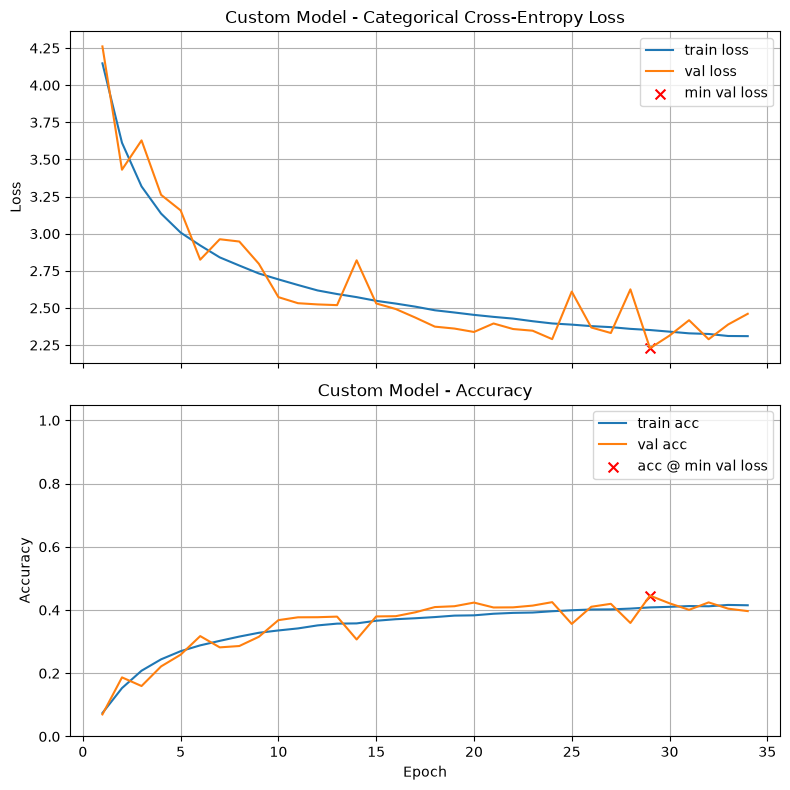

Final Training Loss:            2.3102
Final Training Accuracy:        0.4151
Final Validation Loss:          2.4606
Final Validation Accuracy:      0.3966
Minimum Validation Loss:        2.2288 (Epoch 29)
Validation Accuracy @ Min Loss: 0.4456

Execution Time: 00:27:26


In [13]:
custom_model_history = train_and_test(custom_model, title="Custom Model", verbose=0, return_history=True)

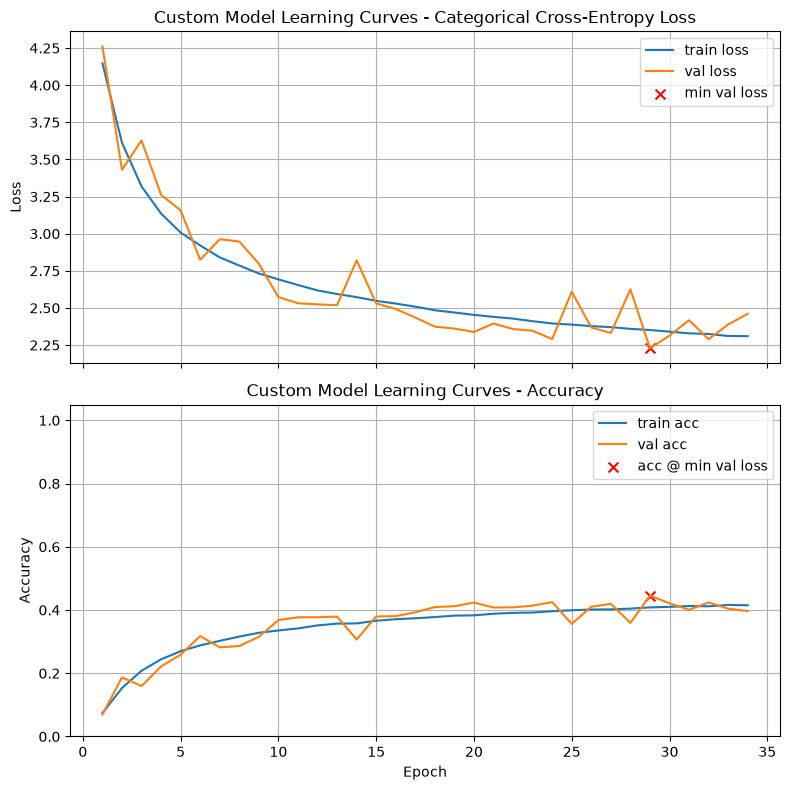

Final Training Loss:            2.3102
Final Training Accuracy:        0.4151
Final Validation Loss:          2.4606
Final Validation Accuracy:      0.3966
Minimum Validation Loss:        2.2288 (Epoch 29)
Validation Accuracy @ Min Loss: 0.4456


In [14]:
plot_learning_curves(custom_model_history, "Custom Model Learning Curves")

### Custom Model Training - Stacked Convolutional Layers (6 Layers with 32, 32, 64, 64, 128, 128 Filters)

In [15]:
def conv_block_v2(filters):
    return [
        Conv2D(filters, 3, activation="relu", kernel_initializer=he, padding="same"),
        BatchNormalization(),
        Conv2D(filters, 3, activation="relu", kernel_initializer=he, padding="same"),
        BatchNormalization(),
        MaxPooling2D()
    ]

custom_model_v2 = Sequential([
    Input(shape=(*IMAGE_SIZE, 3)), # 128x128 with 3 channels (RGB)
    preprocessing_layers,  # rescale + augment during training
    *conv_block_v2(32),
    *conv_block_v2(64),
    *conv_block_v2(128),
    GlobalAveragePooling2D(),
    Dropout(0.4),

    # Compact head
    Dense(128, activation='relu', kernel_initializer=he),
    Dense(num_classes, activation='softmax')
])


Custom Model V2



I0000 00:00:1795640016.307815   37935 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795640016.669355   37937 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
I0000 00:00:1795640017.039343   37939 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn 

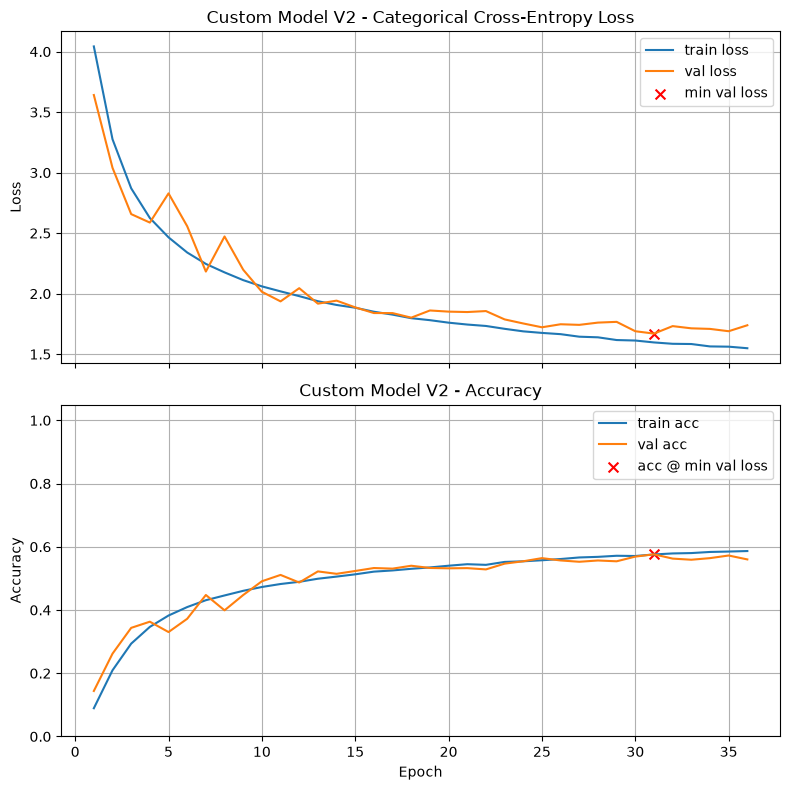

Final Training Loss:            1.5490
Final Training Accuracy:        0.5866
Final Validation Loss:          1.7388
Final Validation Accuracy:      0.5601
Minimum Validation Loss:        1.6698 (Epoch 31)
Validation Accuracy @ Min Loss: 0.5762

Execution Time: 00:49:16


In [16]:
custom_model_v2_history = train_and_test(custom_model_v2, title="Custom Model V2", verbose=0, return_history=True)

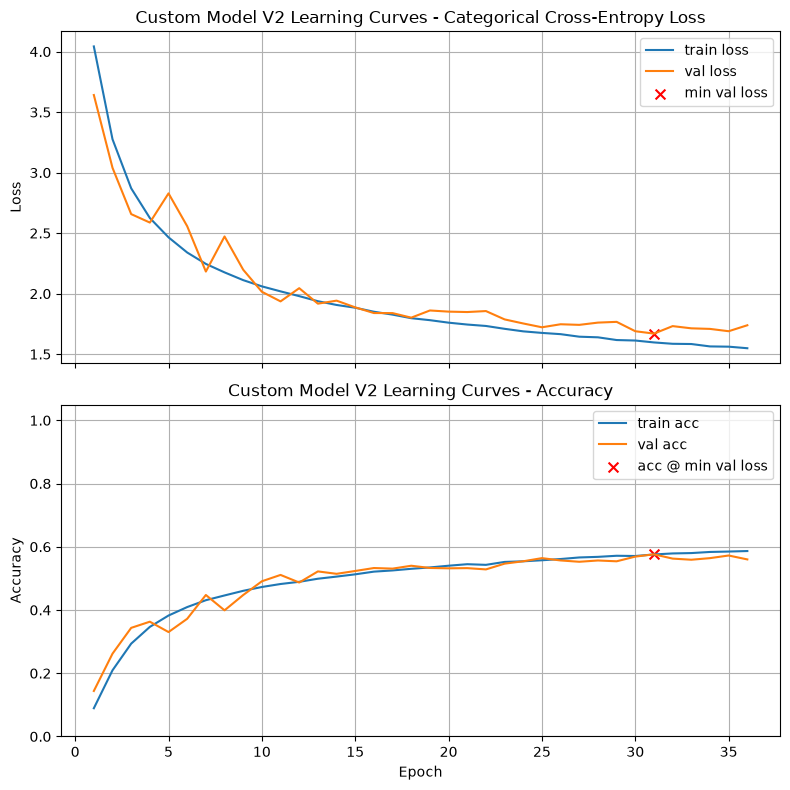

Final Training Loss:            1.5490
Final Training Accuracy:        0.5866
Final Validation Loss:          1.7388
Final Validation Accuracy:      0.5601
Minimum Validation Loss:        1.6698 (Epoch 31)
Validation Accuracy @ Min Loss: 0.5762


In [17]:
plot_learning_curves(custom_model_v2_history, "Custom Model V2 Learning Curves")

**Your Answer:**

> State the hypothesis motivating your improvement experiment, identify what changed between configurations, and explain the expected benefit and any trade-offs.

The hypothesis motivating the improved experiment is that increasing the number of convolutional layers from three to six with BatchNormalization and Dropout will improve representational learning by allowing the model to learn more complex hierarchical features.

The expected benefit as we add more convolutional layers is increase representational learning, which could lead to higher validation accuracy as the model can generalize better. The risk of making the convolutional stack larger, however, is that training time can increase and there is risk of overfitting.

In the first custom model experiment we saw improved generalization. At the epoch of minimal validation loss the validation accuracy increased from 0.1744 to 0.4301 at 2.2712 validation loss (epoch 23), a significant improvement. To determine whether further increasing the number of layers continues to boost performance, I created a targeted experiment increasing the number of convolutional layers from three to six with 32, 32, 64, 64, 128, and 128 filters. Otherwise the model architecture was kept the same. After running the experiment, I saw increased validation accuracy of 0.5813 at a minimum validation loss of 1.6260. These results show that increasing the number of convolutional layers in the model helped to improve performance measured by validation accuracy.


### Part C — Analyze Custom Model Results (10 pts)

**Results (6 pts):**

- Present an organized, side-by-side **validation comparison** of the milestone baseline, initial custom network, and improved custom network.
  - Include the primary selection metric, at least one supporting metric, and relevant training/validation learning curves.
  - Clearly identify the experimental configurations being compared.
- Identify the best custom configuration using the previously declared selection metric. **Do not use test results for model selection.**

**Interpretation (4 pts):**

- Evaluate whether your improvement hypothesis was supported by the validation results, citing specific evidence.
- Discuss evidence of underfitting or overfitting, generalization, and any trade-offs between model performance and computational cost.
- Explain what you learned about model architecture, training, or optimization and how these findings will inform your subsequent experiments.
- If the custom models did not outperform the milestone baseline, explain what the results suggest rather than concealing or dismissing the outcome.

In [18]:
def plot_validation_comparison(histories):
    fig, (loss_ax, acc_ax) = plt.subplots(1, 2, figsize=(14, 5))

    for name, history in histories.items():
        h = history.history
        epochs = range(1, len(h["val_loss"]) + 1)
        color = loss_ax.plot(
            epochs, h["loss"], "--", label=f"{name} train"
        )[0].get_color()

        best_idx = int(np.argmin(h["val_loss"]))

        loss_ax.plot(
            epochs, h["val_loss"], color=color, label=f"{name} validation"
        )
        loss_ax.scatter(
            best_idx + 1, h["val_loss"][best_idx],
            color=color, marker="x"
        )

        acc_ax.plot(epochs, h["accuracy"], "--", color=color, label=f"{name} train")
        acc_ax.plot(
            epochs, h["val_accuracy"], color=color, label=f"{name} validation"
        )
        acc_ax.scatter(
            best_idx + 1, h["val_accuracy"][best_idx],
            color=color, marker="x"
        )

    loss_ax.set(title="Loss", xlabel="Epoch", ylabel="Categorical cross-entropy")
    acc_ax.set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
    acc_ax.set_ylim(0, 1.05)

    for ax in (loss_ax, acc_ax):
        ax.grid(True)
        ax.legend()

    fig.tight_layout()
    plt.show()

In [27]:
custom_model_results = []
for model_name, history in zip(
    (
        "Baseline (128x128x3 input, 3x3 conv 32 filters, Max Pooling, Global Average Pooling, 128 Dense, 101 Classification Head)",
        "Custom Model (128x128x3 input, three 3x3 conv [32, 64, 128 filters] with BatchNormalization and MaxPooling, Global Average Pooling, Dropout 128 Dense, 101 Classification Head)",
        "Custom Model (128x128x3 input, six 3x3 conv [32, 32, 64, 64, 128, 128 filters] with BatchNormalization and MaxPooling, Global Average Pooling, Dropout 128 Dense, 101 Classification Head)"
    ),
    (
        baseline_history,
        custom_model_history,
        custom_model_v2_history
    )
):
    val_losses = history.history['val_loss']
    min_val_loss = min(val_losses)
    min_val_epoch = val_losses.index(min_val_loss)
    val_acc_at_min_loss = history.history['val_accuracy'][min_val_epoch]   
    custom_model_results.append(
        {
            'Model': model_name,
            'Training Loss': f"{history.history['loss'][-1]:.4f}",
            'Training Accuracy': f"{history.history['accuracy'][-1]:.4f}",
            'Validation Loss': f"{history.history['val_loss'][-1]:.4f}",
            'Validation Accuracy': f"{history.history['val_accuracy'][-1]:.4f}",
            'Minimum Validation Loss': min_val_loss,
            'Validation Accuracy @ Min Loss': val_acc_at_min_loss,
        }
    )
    

custom_model_results_df = pd.DataFrame(custom_model_results)
custom_model_results_df

,Model,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Minimum Validation Loss,Validation Accuracy @ Min Loss
0,"Baseline (128x128x3 input, 3x3 conv 32 filters...",3.4735,0.1857,3.5801,0.1727,3.551536,0.175463
1,"Custom Model (128x128x3 input, three 3x3 conv ...",2.3102,0.4151,2.4606,0.3966,2.228773,0.445589
2,"Custom Model (128x128x3 input, six 3x3 conv [3...",1.5490,0.5866,1.7388,0.5601,1.669827,0.576196


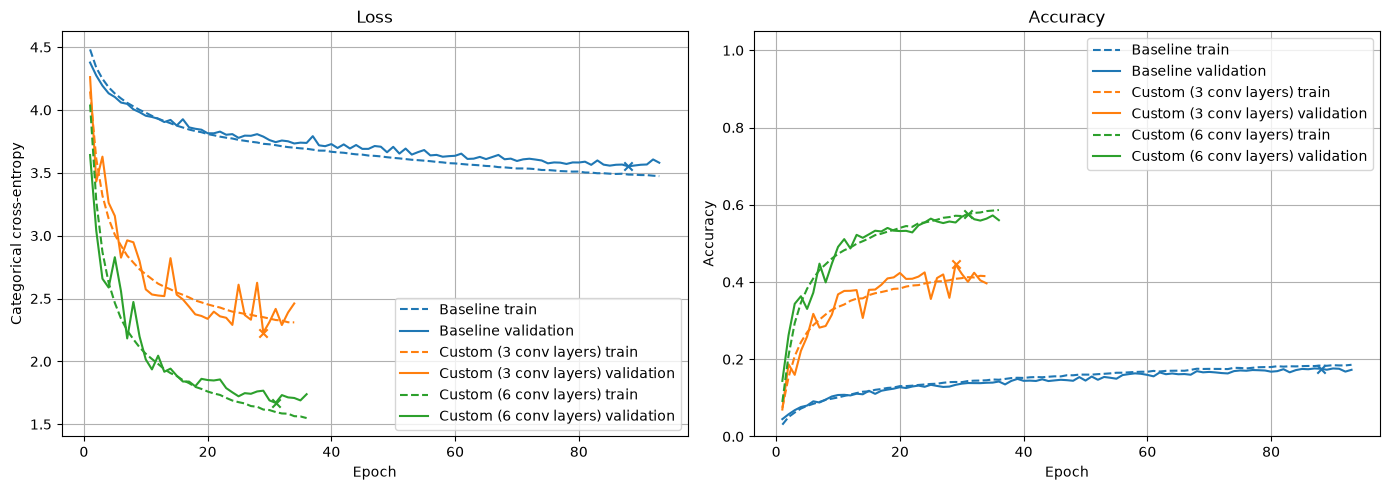

In [28]:
plot_validation_comparison({
    "Baseline": baseline_history,
    "Custom (3 conv layers)": custom_model_history,
    "Custom (6 conv layers)": custom_model_v2_history,
})

**Interpretation: Your Answer:**

The improvement hypothesis is supported by the validation results. As shown in the table above, the validation accuracy at the minimal validation loss increases from 0.430142 to 0.552332. The minimum-validation-loss epoch changed from 23 to 16

The improvement experiment and original custom model both show increased generalization over the baseline model. In terms of trade-offs, the improvement experiment took longer to train with 30 minutes of execution as opposed to the original custom model with 23 minutes. On less powerful hardware, this difference could be more meaningful-but in context of the Nvidia 4060ti used in this project the training times are both well within the 1 hour self imposed training limit. Otherwise, I reccomend the improvement experiment model since it has significantly higher validation accuracy for a small training execution time trade off.

Through these experiments, I discovered that training a model on the Image 101 dataset could require a larger number of convolutional layers than I expected to achieve strong performance. I also found that using six stacked layers is still not enough to acheive validation accuracy higher than ~0.55. This could indicate that even more complex models are required, or that models struggled to generalize for ambiguous categories in the dataset. The classification report could be examined for futher experiments to determine if categories should be combined to increase performance, or whether changes to the architecture should be made instead. Another takeaway is that the 1 hour training timeline was more than enough to train each of the models. For continued experiments, I would experiment with more layers and more filters to attempt to increase representational learning capacity further.

## Problem 3 — Pretrained Models and Transfer Learning (35 pts)

In this problem, you will investigate whether **transfer learning** can improve performance on your classification task. Select an appropriate pretrained model, adapt it to your dataset, and evaluate different strategies for using its pretrained representations.

You will:

- Select a suitable pretrained architecture and adapt its classification head to your task.
- Implement and train an initial **frozen-backbone (feature-extraction)** model.
- Experiment with at least one additional transfer-learning strategy, such as partial unfreezing, fine-tuning, or parameter-efficient adaptation.
- Compare the configurations using **validation results only**, considering both predictive performance and computational efficiency.

> **A. Pretrained model selection and implementation (12 pts)**  
> **B. Transfer-learning and fine-tuning experiment (13 pts)**  
> **C. Results, efficiency, and interpretation (10 pts)**

### Part A —Select and Implement a Pretrained Model (12 pts)

**Implementation (9 pts):**

- Select a publicly available pretrained architecture and identify its pretrained weights or checkpoint.
- Apply the required preprocessing, such as image transformations or text tokenization.
- Adapt the classification head to the number of classes in your dataset.
- Configure an initial **frozen-backbone model**, keeping the pretrained backbone fixed and the classification head trainable. Training is performed in Part B.
- Display the model architecture or summary, including total and trainable parameter counts.

**Rationale (3 pts):**

Explain why the pretrained model is appropriate for your classification task. Discuss the potential benefits of its learned representations and any relevant limitations, such as domain mismatch, model complexity, or computational requirements.

In [21]:
# ALWAYS construct a new instance to avoid sharing layers across models.

def make_base_model_pooled(trainable=False):
    base = tf.keras.applications.mobilenet_v2.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(*IMAGE_SIZE, 3),
        pooling="avg",
    )
    base.trainable = trainable
    return base


base = make_base_model_pooled()

print("Some statistics on the model:")
print("Total Keras layers:", len(base.layers))

# Count unique inverted-residual blocks by their prefix 'block_<n>'
block_ids = sorted({
    int(layer.name.split("_")[1])
    for layer in base.layers
    if layer.name.startswith("block_")
})
print("Conv Block IDs:", block_ids, "(count:", len(block_ids), ")")

# Check whether the final Conv_1 stage exists
has_conv1 = any(
    layer.name.startswith("Conv_1")
    for layer in base.layers
)

print("Has Conv_1 stage:", has_conv1)
print("Model Output Shape:", base.output_shape)

Some statistics on the model:
Total Keras layers: 155
Conv Block IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16] (count: 16 )
Has Conv_1 stage: True
Model Output Shape: (None, 1280)


In [22]:
# P3.A — Load the pretrained model and apply the required preprocessing.
# Adapt the classification head and freeze the pretrained backbone,
# leaving the classification head trainable.

# Construct a fresh frozen MobileNetV2 backbone
from tensorflow.keras.applications import mobilenet_v2
from tensorflow.keras.layers import Lambda

base_model = make_base_model_pooled()

mobile_net_baseline = models.Sequential([
    Input(shape=(*IMAGE_SIZE, 3)),
    Lambda(mobilenet_v2.preprocess_input),
    base_model,
    Dense(num_classes, activation='softmax')
])

In [23]:
# P3.A — Display the pretrained model configuration.
# Show the model architecture, pretrained checkpoint, classification head,
# and total, trainable, and frozen parameter counts.

mobile_net_baseline.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 101)            │       129,381 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,387,365 (9.11 MB)

 Trainable params: 129,381 (505.39 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**Your Answer:**

> Explain why the pretrained model is appropriate for your classification task. Discuss the potential benefits of its learned representations and any relevant limitations, such as domain mismatch, model complexity, or computational requirements.

The pretrained MobileNetV2 model is appropriate for this image classification task since it balances low model complexity that can run on edge devices and single GPUs while still containing a pretrained backbone which can be adapted to the Food 101 dataset. This model's benefits are that it has low compute requirements which can allow us to more quickly retrain its backbone through fine tuning. It also could reduce training time since it already has learned the lower level features that our dataset requires such as lines, edges, colors, and shapes. The potential limitations of this model is that it has less parameters than more complex models like EfficientNet, so it could have less strong performance. 

### Part B — Train and Evaluate Transfer-Learning Strategies (13 pts)

**Implementation (10 pts):** Train a frozen-feature model and at least one controlled adaptation strategy, such as partial unfreezing, full fine-tuning, or parameter-efficient fine-tuning. Document the learning rate(s), optimizer, epochs, stopping criterion, trainable layers, batch size, and training time. Use **validation** for comparison; do not use the test set. If full fine-tuning is infeasible, choose and justify a feasible alternative rather than claiming it was performed.

**Experiment statement (3 pts):** State the rationale and hypothesis for the adaptation strategy and explain how you guarded against unstable updates or overfitting.

#### Baseline


MobileNetV2 Baseline



/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795643446.451201   57752 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795643446.821287   57754 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92

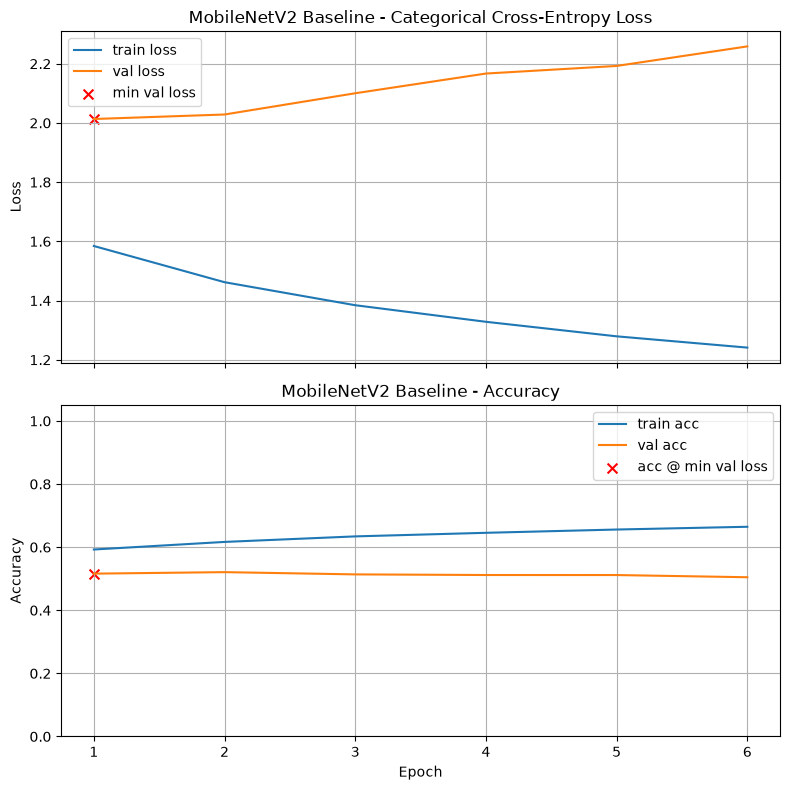

Final Training Loss:            1.2411
Final Training Accuracy:        0.6646
Final Validation Loss:          2.2586
Final Validation Accuracy:      0.5047
Minimum Validation Loss:        2.0133 (Epoch 1)
Validation Accuracy @ Min Loss: 0.5161

Execution Time: 00:03:03


In [29]:
# P3.B — Train the frozen-backbone model from Part A.
# Implement and train at least one additional adaptation strategy
# (e.g., partial unfreezing, full fine-tuning, or parameter-efficient tuning).
# Record training configurations, histories, and training times.

mobile_net_baseline_history = train_and_test(mobile_net_baseline, title="MobileNetV2 Baseline", return_history=True)
mobile_net_baseline_history


#### Partial Unfreezing


Partially Unfrozen MobileNetV2 with N=20



I0000 00:00:1795643631.182946   59343 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795643631.556129   59355 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
I0000 00:00:1795643631.899128   59357 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn 

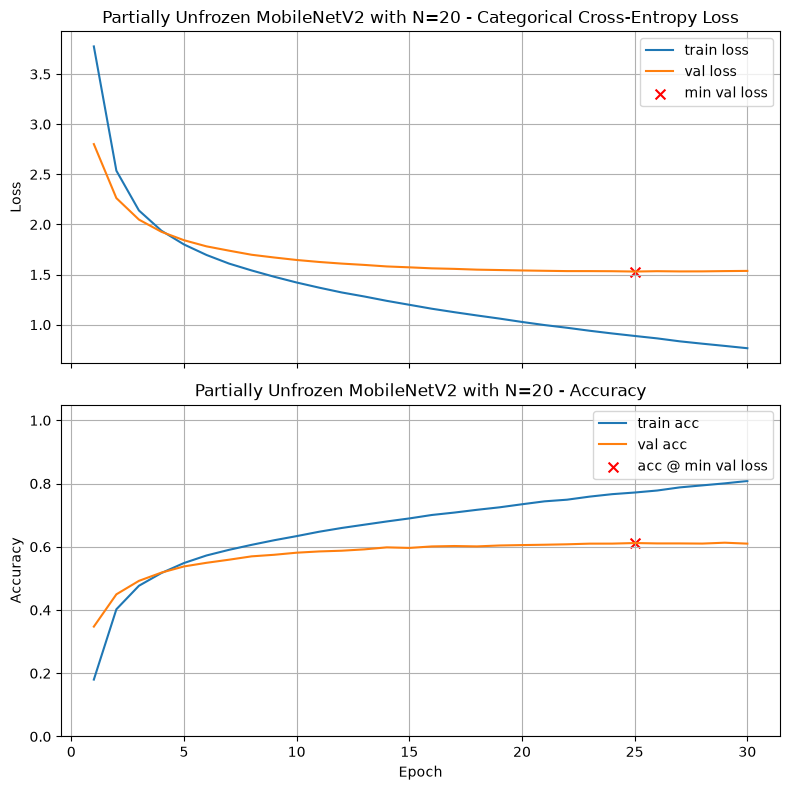

Final Training Loss:            0.7652
Final Training Accuracy:        0.8081
Final Validation Loss:          1.5366
Final Validation Accuracy:      0.6100
Minimum Validation Loss:        1.5301 (Epoch 25)
Validation Accuracy @ Min Loss: 0.6118

Execution Time: 00:15:50


In [30]:
N = 20

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

mobile_net_partial_unfreezing_n20 = models.Sequential([
    Input(shape=(*IMAGE_SIZE, 3)),
    Lambda(mobilenet_v2.preprocess_input),
    base_model,
    Dense(num_classes, activation='softmax')
])

mobile_net_partial_unfreezing_n20_history = train_and_test(mobile_net_partial_unfreezing_n20, title="Partially Unfrozen MobileNetV2 with N=20", lr_schedule=1e-5, return_history=True)
mobile_net_partial_unfreezing_n20_history

#### Partial Unfreezing - Tuning Number of Layers to Unfreeze


Partially Unfrozen MobileNetV2 with N=40



I0000 00:00:1795644584.240105   67289 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795644584.598255   67291 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
I0000 00:00:1795644584.960809   67293 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn 

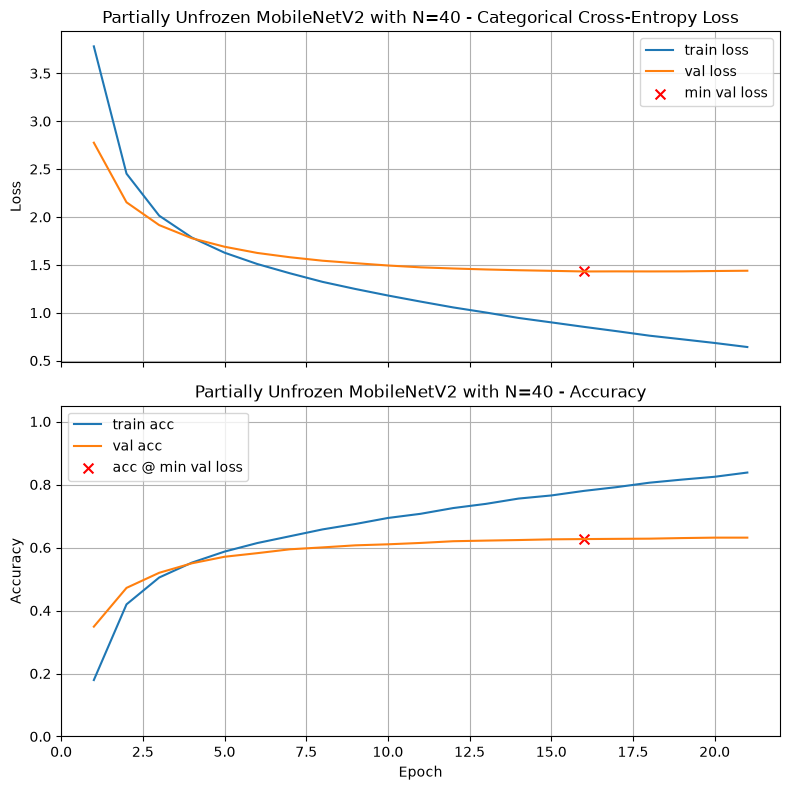

Final Training Loss:            0.6418
Final Training Accuracy:        0.8380
Final Validation Loss:          1.4384
Final Validation Accuracy:      0.6313
Minimum Validation Loss:        1.4307 (Epoch 16)
Validation Accuracy @ Min Loss: 0.6268

Execution Time: 00:12:12


In [31]:
N = 40

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

mobile_net_partial_unfreezing_n40 = models.Sequential([
    Input(shape=(*IMAGE_SIZE, 3)),
    Lambda(mobilenet_v2.preprocess_input),
    base_model,
    Dense(num_classes, activation='softmax')
])

mobile_net_partial_unfreezing_n40_history = train_and_test(mobile_net_partial_unfreezing_n40, title="Partially Unfrozen MobileNetV2 with N=40", lr_schedule=1e-5, return_history=True)
mobile_net_partial_unfreezing_n40_history

#### Summary of Pretrained Models

In [32]:
pretrained_results = []
for model_name, history in zip(
    (
        "Pretrained MobileNetV2 - Frozen",
        "Pretrained MobileNetV2 - Partially Frozen (N=20)",
        "Pretrained MobileNetV2 - Partially Frozen (N=40)"
    ),
    (
        mobile_net_baseline_history,
        mobile_net_partial_unfreezing_n20_history,
        mobile_net_partial_unfreezing_n40_history
    )
):
    val_losses = history.history['val_loss']
    min_val_loss = min(val_losses)
    min_val_epoch = val_losses.index(min_val_loss)
    val_acc_at_min_loss = history.history['val_accuracy'][min_val_epoch]   
    pretrained_results.append(
        {
            'Model': model_name,
            'Training Loss': f"{history.history['loss'][-1]:.4f}",
            'Training Accuracy': f"{history.history['accuracy'][-1]:.4f}",
            'Validation Loss': f"{history.history['val_loss'][-1]:.4f}",
            'Validation Accuracy': f"{history.history['val_accuracy'][-1]:.4f}",
            'Minimum Validation Loss': min_val_loss,
            'Validation Accuracy @ Min Loss': val_acc_at_min_loss,
        }
    )
    

pretrained_results_df = pd.DataFrame(pretrained_results)
pretrained_results_df

,Model,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Minimum Validation Loss,Validation Accuracy @ Min Loss
0,Pretrained MobileNetV2 - Frozen,1.2411,0.6646,2.2586,0.5047,2.013303,0.516091
1,Pretrained MobileNetV2 - Partially Frozen (N=20),0.7652,0.8081,1.5366,0.6100,1.530081,0.611843
2,Pretrained MobileNetV2 - Partially Frozen (N=40),0.6418,0.8380,1.4384,0.6313,1.430715,0.626795


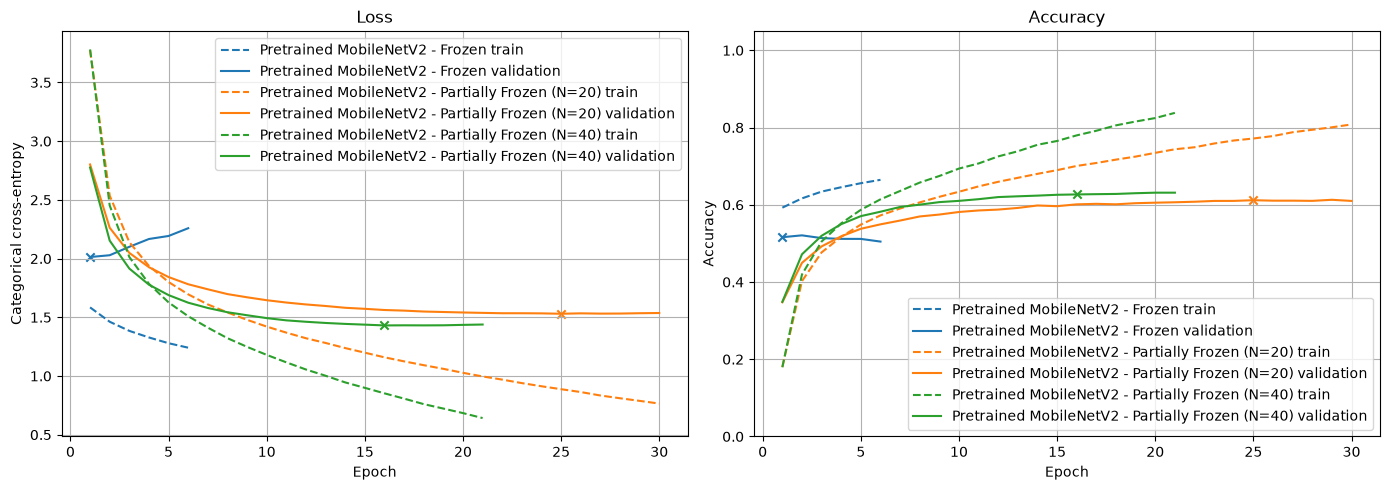

In [33]:
plot_validation_comparison({
    "Pretrained MobileNetV2 - Frozen": mobile_net_baseline_history,
    "Pretrained MobileNetV2 - Partially Frozen (N=20)": mobile_net_partial_unfreezing_n20_history,
    "Pretrained MobileNetV2 - Partially Frozen (N=40)": mobile_net_partial_unfreezing_n40_history,
})

**Your Answer:**

> State the rationale and hypothesis for the adaptation strategy and explain how you guarded against unstable updates or overfitting.

A frozen backbone with trainable classification head was evaluated against two partially unfrozen backbone models with varying number of unfrozen layers. The frozen model provides the baseline using the MobileNetV2's pretrained feature set. By unfreezing varying numbers of layers (20 and 40), we can validate whether adapting more or less of the backbone to the specific Food 101 dataset has the most impact on generalization. As we unfreeze more layers, there is more flexibility for the model to fit the dataset with increased risk of overfitting and less training stability. To guard against unstable updates I use a low learning rate and to guard against overfitting we use partial unfrozen models rather than a fully unfrozen configuration.

### Part C — Compare Performance and Computational Efficiency (10 pts)

**Results (6 pts):** 

- Compare the pretrained configurations with each other and with the best custom model on the **same or explicitly comparable validation data**.
- Include the primary metric, secondary metric(s), approximate runtime, and computational cost/proxy (e.g., trainable parameters, batch size, or memory if measured).
- Identify the preferred pretrained configuration using the previously declared primary validation metric.

**Interpretation (4 pts):** 

- Discuss gains, failures, convergence, generalization, and the trade-offs associated with pretraining and fine-tuning.
- State explicitly if comparisons are limited by differences in datasets, training budgets, or computational resources.
- Discuss whether the performance improvements justify the additional computational cost.

In [36]:
# P3.C — Compare validation results for the pretrained configurations
# and the best custom model from Problem 2.
# Display primary and supporting metrics, training times,
# and relevant measures of computational cost.
# Use the same or explicitly comparable validation data.

all_results = pd.concat([custom_model_results_df, pretrained_results_df]).reset_index(drop=True)
all_results

,Model,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Minimum Validation Loss,Validation Accuracy @ Min Loss
0,"Baseline (128x128x3 input, 3x3 conv 32 filters...",3.4735,0.1857,3.5801,0.1727,3.551536,0.175463
1,"Custom Model (128x128x3 input, three 3x3 conv ...",2.3102,0.4151,2.4606,0.3966,2.228773,0.445589
2,"Custom Model (128x128x3 input, six 3x3 conv [3...",1.5490,0.5866,1.7388,0.5601,1.669827,0.576196
3,Pretrained MobileNetV2 - Frozen,1.2411,0.6646,2.2586,0.5047,2.013303,0.516091
4,Pretrained MobileNetV2 - Partially Frozen (N=20),0.7652,0.8081,1.5366,0.6100,1.530081,0.611843
5,Pretrained MobileNetV2 - Partially Frozen (N=40),0.6418,0.8380,1.4384,0.6313,1.430715,0.626795


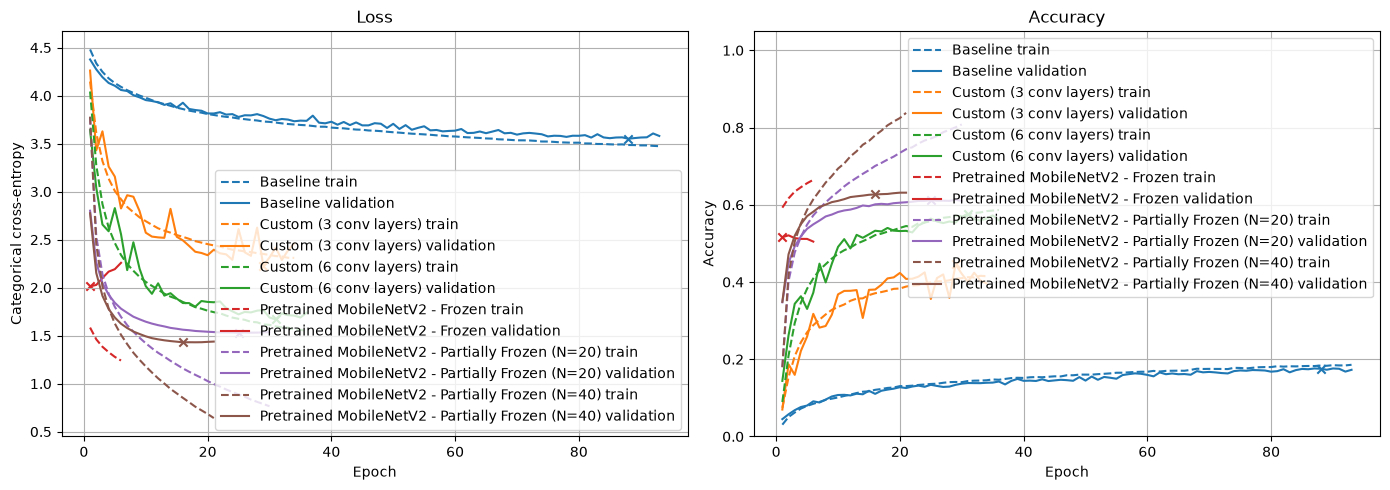

In [42]:
# P3.C — Visualize performance and computational trade-offs.
# Create plots comparing validation performance with training time
# or another meaningful measure of computational cost.
# Clearly label models and configurations.

# YOUR CODE HERE
plot_validation_comparison({
    "Baseline": baseline_history,
    "Custom (3 conv layers)": custom_model_history,
    "Custom (6 conv layers)": custom_model_v2_history,
    "Pretrained MobileNetV2 - Frozen": mobile_net_baseline_history,
    "Pretrained MobileNetV2 - Partially Frozen (N=20)": mobile_net_partial_unfreezing_n20_history,
    "Pretrained MobileNetV2 - Partially Frozen (N=40)": mobile_net_partial_unfreezing_n40_history,
})

**Interpretation: Your Answer:**

The custom model and pretrained model variants are compared across the same train/validation split. Therefore the comparison of the models are not limited by difference in datasets. The validation accuracy at the minimum validation loss are compared for each model as the primary metric. Additionally, the training time is evaluated as a secondary metric to balance model complexity with performance. 

Of the custom models, the variant with six 3x3 convolutional layers (32, 32, 64, 64, 128, 128 filters) and a Dense head is the optimal model, with 0.552332 validation accuracy at the minimum validation loss of 1.748917 with 30 minutes of training time. 

The frozen pretrained MobileNetV2 was not able to outperform the custom model, receiving 0.518566 validation accuracy at a minimum validation loss of 1.967430. Both partially unfrozen models received higher accuracy than the custom model with 0.607486 for the 20 unfrozen layer model. and 0.632637 for the 40 unfrozen layer model. The optimal pretrained model configuration tested was the partially unfrozen MobileNetV2 with 40 layers unfrozen. This model achieved 0.632637 validation accuracy at a minimum validation loss of 1.436487 and 15 minutes of training time.

Comparing the optimal custom model and pretrained model, the MobileNetV2 pretrained model with 40 layers is the reccomended model based on the validation accuracy and training time. Since the pretrained model received ~0.08 increase in validation accuracy in approximately half the training time and can be run on edge devices and single GPUs, it is both better performing model than the custom model and requires less computational cost. Training budgets were not a limiting factor for these experiments since both models comfortably trained within the 1 hour objective.

## Problem 4 — Model Comparison, Selection, and Final Training (30 pts)

Make a principled final choice among the baseline, best custom model, and best pretrained model. The decision must be based **only on validation results and legitimate resource constraints**. Then finalize the selected model, document its training configuration, and establish the protocol for final test-set evaluation.

- **A. Integrated validation comparison (12 pts)**
- **B. Selection and final configuration (10 pts)**
- **C. Final training and evaluation readiness (8 pts)**

### Part A —Compare the Three Model Families (12 pts)

**Results (8 pts):**

- Present a side-by-side **validation comparison** of the milestone baseline, best custom model, and best pretrained model.
- Include the primary selection metric, supporting metrics, and relevant measures of computational cost or model complexity.
- Examine per-class validation performance, using tables or plots where appropriate to identify differences between models.
- Use the same or explicitly comparable validation data. If datasets, subsets, or evaluation procedures differ, explain the limitations and make comparisons consistent where feasible.

**Interpretation (4 pts):**

- Discuss the relative strengths and weaknesses of the three model families, including class-specific performance and evidence of overfitting or underfitting.
- Evaluate trade-offs between predictive performance, model complexity, and computational cost.
- Recommend a preferred model based on the validation evidence, explaining why it represents the best overall choice rather than relying on a single metric.

In [38]:
# P4.A — Consolidate validation results from Problems 1–3.
# Assemble the metrics and computational cost measures
# for the milestone baseline, best custom model, and best pretrained model.

all_results
all_results.loc[[0, 2, 5]]

,Model,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Minimum Validation Loss,Validation Accuracy @ Min Loss
0,"Baseline (128x128x3 input, 3x3 conv 32 filters...",3.4735,0.1857,3.5801,0.1727,3.551536,0.175463
2,"Custom Model (128x128x3 input, six 3x3 conv [3...",1.5490,0.5866,1.7388,0.5601,1.669827,0.576196
5,Pretrained MobileNetV2 - Partially Frozen (N=40),0.6418,0.8380,1.4384,0.6313,1.430715,0.626795


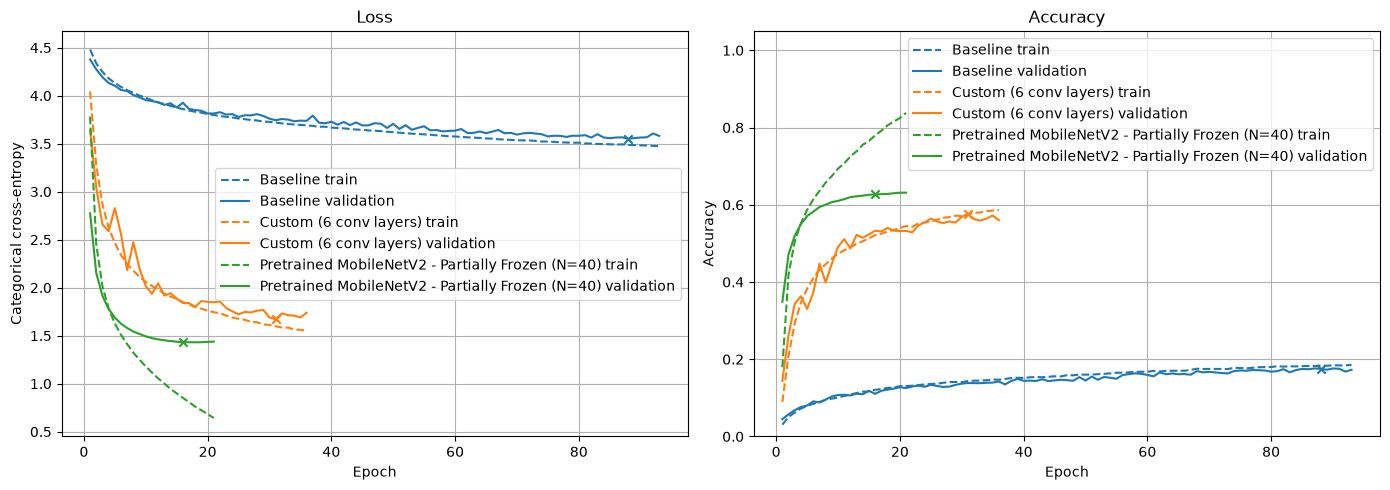

In [39]:
# P4.A — Display the final three-model validation comparison.
# Show primary and supporting metrics, computational costs,
# and relevant per-class diagnostic tables or plots.

plot_validation_comparison({
    "Baseline": baseline_history,
    "Custom (6 conv layers)": custom_model_v2_history,
    "Pretrained MobileNetV2 - Partially Frozen (N=40)": mobile_net_partial_unfreezing_n40_history,
})

In [43]:
from sklearn.metrics import confusion_matrix

# Collect the true validation labels. val_ds is not shuffled.
y_val = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in val_ds
])

# Replace these with different selected model variables if needed.
models = {
    "Baseline": baseline_model,
    "Custom": custom_model_v2,
    "Pretrained": mobile_net_partial_unfreezing_n40,
}

# Calculate per-category accuracy for each model.
class_accuracy = {}

for name, model in models.items():
    probabilities = model.predict(val_ds, verbose=0)
    y_pred = probabilities.argmax(axis=1)

    cm_normalized = confusion_matrix(
        y_val,
        y_pred,
        labels=np.arange(len(food_label_names)),
        normalize="true",
    )
    class_accuracy[name] = pd.Series(
        np.diag(cm_normalized),
        index=food_label_names,
        name=name,
    )

accuracy_by_class = pd.DataFrame(class_accuracy)
accuracy_by_class.index.name = "Category"

I0000 00:00:1795645964.515736   75436 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795645964.522681   75439 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795645964.524870   75438 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795645964.534736   75437 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

In [45]:
# Get each model's 10 lowest-accuracy categories.
baseline_worst = (
    accuracy_by_class["Baseline"]
    .nsmallest(10)
    .rename("Accuracy")
    .rename_axis("Category")
    .reset_index()
)
baseline_worst

,Category,Accuracy
0,breakfast_burrito,0.00
1,gnocchi,0.00
2,beef_tartare,0.01
3,grilled_cheese_sandwich,0.01
4,bread_pudding,0.02
5,cheese_plate,0.02
6,huevos_rancheros,0.02
7,lasagna,0.02
8,shrimp_and_grits,0.02
9,donuts,0.03


In [46]:
custom_worst = (
    accuracy_by_class["Custom"]
    .nsmallest(10)
    .rename("Accuracy")
    .rename_axis("Category")
    .reset_index()
)
custom_worst

,Category,Accuracy
0,bread_pudding,0.16
1,breakfast_burrito,0.23
2,apple_pie,0.24
3,foie_gras,0.24
4,tuna_tartare,0.25
5,gnocchi,0.26
6,steak,0.26
7,ceviche,0.29
8,donuts,0.29
9,cheesecake,0.30


In [47]:
pretrained_worst = (
    accuracy_by_class["Pretrained"]
    .nsmallest(10)
    .rename("Accuracy")
    .rename_axis("Category")
    .reset_index()
)
pretrained_worst

,Category,Accuracy
0,steak,0.28
1,pork_chop,0.29
2,huevos_rancheros,0.30
3,ravioli,0.31
4,tuna_tartare,0.35
5,foie_gras,0.36
6,apple_pie,0.37
7,bread_pudding,0.40
8,ceviche,0.40
9,chocolate_mousse,0.41


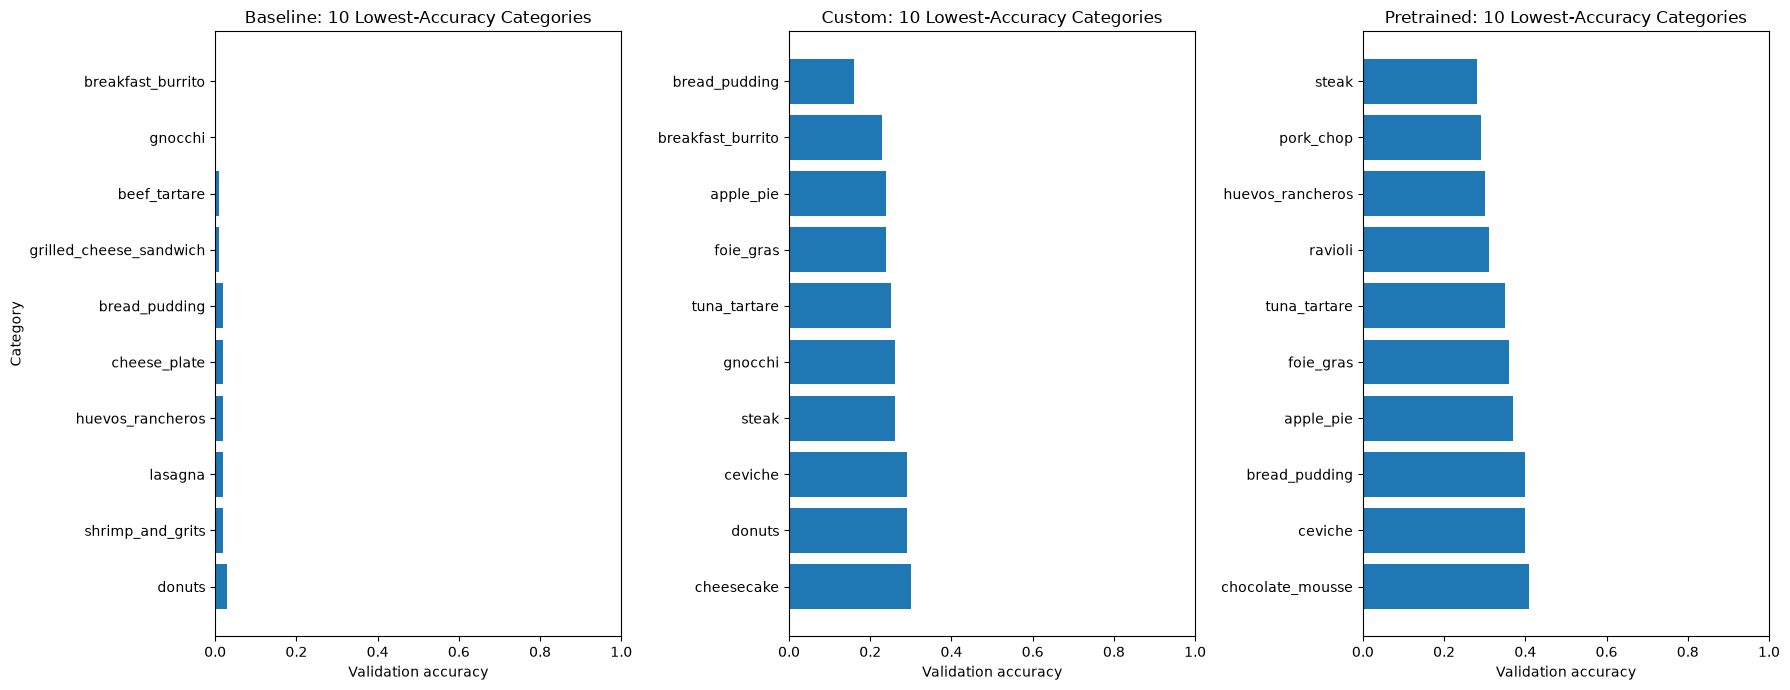

In [48]:
# Plot each model's own 10 worst categories.
fig, axes = plt.subplots(1, len(models), figsize=(18, 7), sharex=True)

for ax, name in zip(axes, models):
    worst = accuracy_by_class[name].nsmallest(10).sort_values()

    ax.barh(worst.index, worst.values)
    ax.set_title(f"{name}: 10 Lowest-Accuracy Categories")
    ax.set_xlabel("Validation accuracy")
    ax.set_xlim(0, 1)
    ax.invert_yaxis()

axes[0].set_ylabel("Category")
fig.tight_layout()
plt.show()

**Interpretation: Your Answer:**

Examining the baseline, optimal custom model, and optimal pretrained model we can see a large separation in performance between the baseline and optimal models. The validation accuracy at the minimum validation loss was 0.175463, as opposed to 0.576196 in the custom model and 0.626795 in the pretrained model. 

Looking at the plot of the validation and training curves, we can see that there is evidence of underfitting in the baseline by the plateaued performance throughhout training. In the custom model we see a tight gap between training and validation performance and continued improvement until slight overfitting begins around epoch 30, where early stopping stops training. Finally, in the pretrained model we see quick improvement in performance until around epoch 15 when early stopping finishes training, where the training and validation gap betweens to widen, suggesting overfitting.

In terms of secondary metrics, the model training time across all three models is within the 1 hour training goal. The pretrained model, which achieved the best performance according to the primary metric, validation accuracy, also receives the fastest training time. In terms of predictive performance and computational efficiency the pretrained model was the most optimal overall.

Examing class specific performance across each model, we see the baseline model receives low accuracy on a number of categories. At least 10 categories received less than 0.02 accuracy. Moving on to the custom model, the lowest accuracy category was the bread_pudding with 0.16 accuracy. For the pretrained model the least accurate cateogry was steak with 0.28. The pretrained model has less outlier categories with poor performance. Looking at the custom and pretrained model, a number of poorly performing categories are common, such as bread_pudding, apple_pie, foie_gras, tuna_tartare, steak, and ceviche. We found in the EDA that the tuna_tartare, steak, and ceviche categories could be problematic due to ambiguity, which could explain the performance issue.

Based on the predictive performance in terms of validation accuracy and the computational efficiency of the optimal pretrained model, it is reccomended as the best overall choice.

### Part B — Choose and Lock the Final Model (10 pts)

**Choice and Rationale (6 pts):**

- Identify your selected model family and configuration.
- Justify your selection based on validation performance, the primary selection metric, and computational constraints.
- Briefly explain why the principal alternatives were not selected.
- State the exact primary selection metric and any tie-breaking criteria.

**Locked Configuration (4 pts):**

Complete the provided `final_config` dictionary, replacing the example values with your final choices. Include:

- Model architecture and pretrained checkpoint (if applicable).
- Preprocessing and training data/subset policy.
- Training hyperparameters, including optimizer, learning rate, and batch size.
- Random seed, stopping criteria, and checkpoint/epoch selection rule.
- Primary and supporting metrics for final evaluation.

**All modeling and evaluation decisions must be fixed before examining test results in Problem 5.**

In [ ]:
N = 40

def make_base_model_pooled(trainable=False):
    base = tf.keras.applications.mobilenet_v2.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(*IMAGE_SIZE, 3),
        pooling="avg",
    )
    base.trainable = trainable
    return base

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

mobile_net_partial_unfreezing_n40 = models.Sequential([
    Input(shape=(*IMAGE_SIZE, 3)),
    Lambda(mobilenet_v2.preprocess_input),
    base_model,
    Dense(num_classes, activation='softmax')
])

mobile_net_partial_unfreezing_n40_history = train_and_test(mobile_net_partial_unfreezing_n40, title="Partially Unfrozen MobileNetV2 with N=40", lr_schedule=1e-5, return_history=True)
mobile_net_partial_unfreezing_n40_history

In [50]:
# P4.B — Document the final model configuration.
# Replace the example values below with your selected model and settings.
# Add or modify entries as appropriate for your architecture.
# All decisions must be fixed before evaluating on the test set.

final_config = {
    "model_family": "pretrained",
    "architecture": "MobileNetV2, include_top=False, global average pooling, softmax classification head",
    "pretrained_checkpoint": "ImageNet weights",
    "preprocessing": "RGB; resize/crop to 128x128; MobileNetV2 preprocess_input",
    "training_data": "Training split only",
    "validation_policy": "Original validation split for early stopping and model comparison",
    "trainable_layers": "Last 40 MobileNetV2 backbone layers plus classification head; earlier backbone layers frozen",
    "optimizer": "Adam",
    "learning_rate": 1e-5,
    "batch_size": 32,
    "max_epochs": 500,
    "stopping_rule": "EarlyStopping on val_loss; patience=5; min_delta=1e-4",
    "weight_restoration": "Restore weights from the epoch with the lowest val_loss",
    "random_seed": 42,
    "primary_metric": "Validation accuracy for comparing models; test accuracy for final evaluation",
    "supporting_metrics": ["Validation loss", "training time"],
}

# Display the locked configuration.
final_config

{'model_family': 'pretrained',
 'architecture': 'MobileNetV2, include_top=False, global average pooling, softmax classification head',
 'pretrained_checkpoint': 'ImageNet weights',
 'preprocessing': 'RGB; resize/crop to 128x128; MobileNetV2 preprocess_input',
 'training_data': 'Training split only',
 'validation_policy': 'Original validation split for early stopping and model comparison',
 'trainable_layers': 'Last 40 MobileNetV2 backbone layers plus classification head; earlier backbone layers frozen',
 'optimizer': 'Adam',
 'learning_rate': 1e-05,
 'batch_size': 32,
 'max_epochs': 500,
 'stopping_rule': 'EarlyStopping on val_loss; patience=5; min_delta=1e-4',
 'weight_restoration': 'Restore weights from the epoch with the lowest val_loss',
 'random_seed': 42,
 'primary_metric': 'Validation accuracy for comparing models; test accuracy for final evaluation',
 'supporting_metrics': ['Validation loss', 'training time']}

**Choice and Rationale: Your Answer:**

I selected the pretrained MobileNetV2 with partially unfrozen backbone (N=40) based on its validation accuracy as the primary metric and on validation loss and training time as secondary metrics. The baseline and custom model variants were rejected due to increased training time and inferior validation accuracy.

### Part C — Produce the Final Trained Model (8 pts)

**Implementation and Evidence (6 pts):**

- Train or restore the selected model using the locked configuration from Part B.
- Choose one of the following approaches:
  - **Retain a validation partition:** Train the model using the training data, with validation-based early stopping or checkpoint selection.
  - **Retrain on combined data:** Use the results of previous validation experiments to establish a fixed training duration, then retrain using the combined training and validation data.
  - **Restore a checkpoint:** Load an already-trained model selected using validation results.
- Record the actual training procedure, including the data used, epochs completed, and final checkpoint or model.
- Save the trained model or checkpoint for reuse, where practical.

**Do not use the test set for training, early stopping, checkpoint selection, or any other model-selection decisions.**

**Protocol Explanation (2 pts):**

- Explain which data were used for final training and validation, if applicable.
- State whether the final model was retrained or restored from a previously selected checkpoint.
- Explain how the final training procedure follows the configuration established in Part B.

In [ ]:
# P4.C — Train or restore the locked final model from Part B.
# Follow the declared training protocol without using test data.
# Save the final model or checkpoint where practical.

# YOUR CODE HERE


In [ ]:
# P4.C — Display evidence of the completed final model.
# Show whether the model was trained or restored, the data used,
# epochs completed or checkpoint restored, and random seed.
# Identify the saved model/checkpoint, if applicable.
# Do not include test results.

# YOUR CODE HERE


**Protocol Explanation: Your Answer:**

*Replace this text with your answer.*

## Problem 5 — Final Test Evaluation and Error Analysis (25 pts)

In this problem, you will evaluate your **locked final model** from Problem 4 on the held-out test set and analyze its performance.

- Evaluate the final model on the test set **only once**, using the previously established evaluation protocol.
- Report the results accurately, including any unexpected or disappointing outcomes.
- Do not modify the model, hyperparameters, or evaluation procedure in response to test results.

**This is the first point in the assignment where test-set performance should be examined or reported.**

> **A. Final test metrics and visualizations (10 pts)**  
> **B. Error analysis (9 pts)**  
> **C. Interpretation and limitations (6 pts)**

### Part A —Evaluate the Locked Model on Test Data (10 pts)

**Implementation and Results (8 pts):**

- Apply the appropriate inference preprocessing and evaluate the locked final model on the held-out test set.
- Report test **accuracy**, **macro-F1**, and any additional metrics used in your validation comparisons.
- Present a labeled confusion matrix (or a readable summary for datasets with many classes).
- Include per-class performance metrics, such as precision, recall, and F1, to identify differences across classes.

**Methodology (2 pts):**

- Report the test-set size, number of classes, and final model/checkpoint used.
- Explain how the test set was kept separate from training, validation, and model selection.
- State whether the evaluation used the entire test set or a subset, and explain any restrictions.

In [ ]:
# P5.A — FIRST TEST-SET EVALUATION.
# Evaluate ONLY the locked final model from Problem 4.
# Apply the required inference preprocessing and generate test predictions.
# Compute accuracy, macro-F1, supporting metrics, and confusion matrix.
# Do not modify or retrain the model based on test results.

# YOUR CODE HERE


In [ ]:
# P5.A — Display final test-set evaluation results.
# Show accuracy, macro-F1, supporting metrics, and per-class performance.
# Display a labeled confusion matrix (or readable summary for many classes).
# Report the test-set size and number of classes.

# YOUR CODE HERE


**Methodology: Your Answer:**

*Replace this text with your answer.*

### Part B — Analyze Errors (9 pts)

**Evidence (6 pts):** Identify the hardest classes and at least two recurring types of errors, using **test-set** confusion patterns, per-class metrics, or representative misclassified examples. When showing examples, use only data appropriate to share and label model predictions and true labels clearly. For a large number of classes, summarize or focus the visualization rather than presenting an unreadable full matrix.

**Interpretation (3 pts):** Explain plausible mechanisms behind those errors, distinguishing evidence from speculation.

In [ ]:
# P5.B — Analyze test-set classification errors.
# Identify the hardest classes using per-class metrics and confusion patterns.
# Find at least two recurring types of misclassification.
# Select representative examples where appropriate.

# YOUR CODE HERE


In [ ]:
# P5.B — Display error-analysis results.
# Show the hardest classes and their relevant performance metrics.
# Display evidence of at least two recurring error patterns,
# using confusion summaries or labeled misclassified examples.
# Avoid unreadable plots for datasets with many classes.

# YOUR CODE HERE


**Your Answer:**

> Explain plausible mechanisms behind those errors, distinguishing evidence from speculation.

*Replace this text with your answer.*

### Part C — Interpret the Final Outcome (6 pts)

**Interpretation and Generalization:**

- Compare the final test performance with the validation results. Discuss whether the results suggest that the model generalizes well to unseen data.
- Explain any notable differences between validation and test performance.

**Limitations and Future Improvements:**

- Identify **two specific limitations** of the final model or experimental approach, supported by your results.
- Propose **two concrete improvements** that could address these limitations, explaining why they might help.

**Final Reflection:**

- Summarize the most important technical lesson you learned about model development, training, or evaluation.

**Do not modify or reevaluate the model based on test results.** Proposed improvements are for future work. The technical report will explore these findings in greater detail.

**Your Answer:**

*Replace this text with your answer.*

## AI-Use Disclosure (required; no separate points)

Consistent with CDS policy, disclose any generative AI tools used in the project. State what tasks the tools assisted with, what you independently verified, and important limitations or errors you found. If you did not use such tools, say so.

**Your Answer:**

*Replace this text with your answer.*